# Computer vision libraries in Pytorch

* `torchvision` - base domain library for Pytorch Computer Vision
* `torchvision.datasets` - get datasets and data loading functions for computer vision
* `torchvision.models` - get pretrained computer vision models that you can leverage for your own problems
* `torchvision.transforms` - functions for manipulating your vision data(images) to be suitable for use with an ML model
* `torch.utils.data.Dataset` - Base dataset class for PyTorch
* `torch.utils.data.Dataloader` - creates python iterables over a dataset

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import torch
from torch import nn

# Import torchvision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# Visualization
import matplotlib.pyplot as plt

print(torch.__version__)
print(torchvision.__version__)


2.14.0+cu130
0.29.0+cu130


## 1. Getting a dataset

In [3]:
# Setup training data 
train_data = datasets.FashionMNIST(
    root='data',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)

test_data = datasets.FashionMNIST(
    root='data',
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [4]:
len(train_data), len(test_data)

(60000, 10000)

In [5]:
# See the first training example
image , label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [6]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [7]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

### 1.1 Check the shape

In [8]:
print(f"Image shape:{image.shape} -> [color_channels, height, width]")
print(f"Label:{class_names[label]}")

Image shape:torch.Size([1, 28, 28]) -> [color_channels, height, width]
Label:Ankle boot


### 1.2 Visualizing our data 

Image Shape:torch.Size([1, 28, 28])


Text(0.5, 1.0, '9')

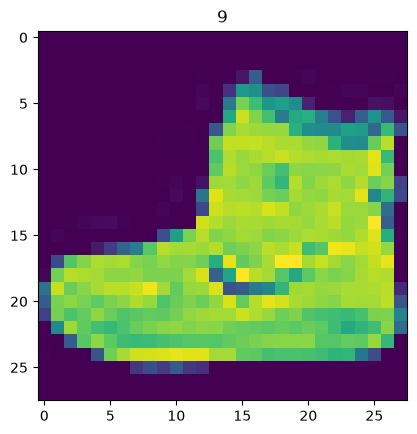

In [9]:
image , label = train_data[0]
print(f"Image Shape:{image.shape}")
plt.imshow(image.squeeze())
plt.title(label)
#image

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

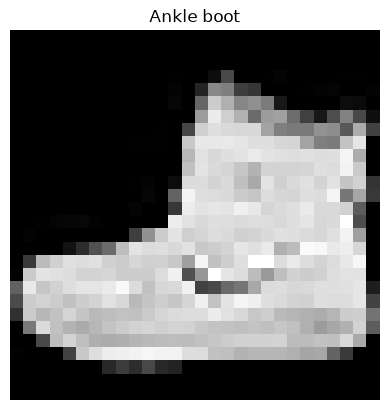

In [10]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis(False)

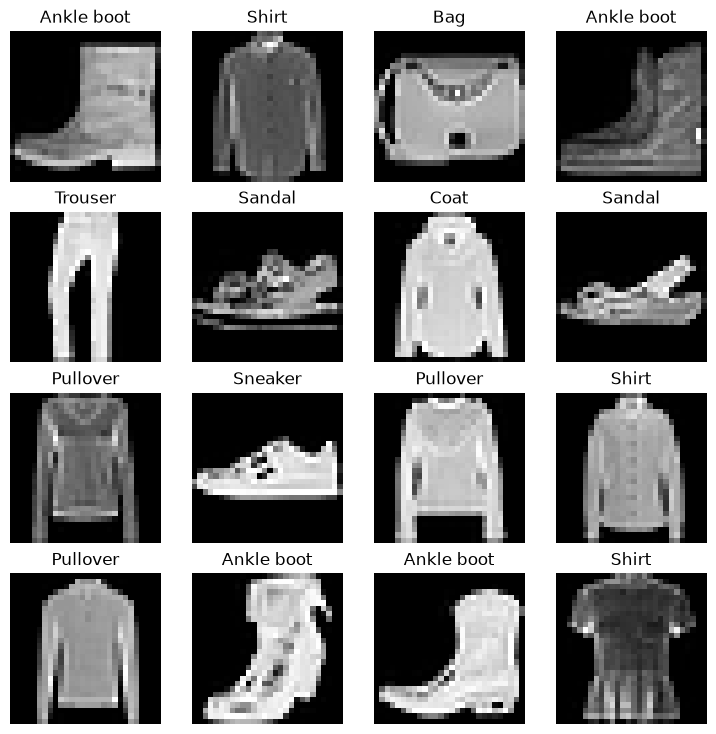

In [11]:
# PLot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(9,9))
rows, cols = 4,4
for i in range(1, rows*cols+1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.axis(False)

## 2. Prepare Dataloader

#### Dataloader turn our data into Python iterables.

#### More specifically we want to turn or data into mini batches 

#### Why should we do this?
* It is more computationally efficient as in your computing hardware may not be able to look (store in memory) at 60000 images in one hit. So we break it down to 32 images (batch size of 32)
* It gives our neural networks more chances to update its gradients per epoch (this means our neural network updates the internal states its weights and biases every 32 images thanks to the optimizer and this is even more efficient)

In [12]:
from torch.utils.data import DataLoader

#setup the batch size the hyperparameter
BATCH_SIZE = 32

# turn datasets into iterables (batches)
train_dataloader = DataLoader(dataset=train_data,
                             batch_size=BATCH_SIZE,
                             shuffle=True)

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             shuffle=False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x22ef2491550>,
 <torch.utils.data.dataloader.DataLoader at 0x22ef36d6710>)

In [13]:
len(train_dataloader), len(test_dataloader)

(1875, 313)

In [14]:
60000/32, 10000/32

(1875.0, 312.5)

In [15]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size:torch.Size([1, 28, 28])
Label:6, label size:torch.Size([])


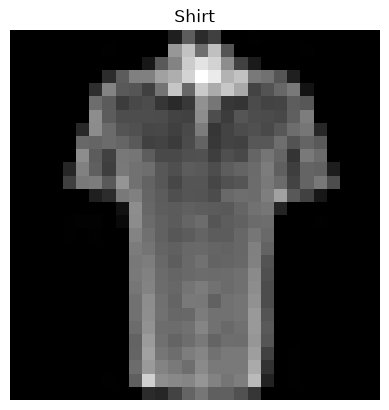

In [16]:
# Show a sample
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis(False)
print(f"Image size:{img.shape}")
print(f"Label:{label}, label size:{label.shape}")

## 3. Baseline Model 
* When starting machine learning model it's a good practice to start with a baseline model.
* A baseline model is a simple model you will try and improve upon with subsequent models.
* In short start simple and then add more complexity when necessary

In [17]:
# Create a model
flatten_model = nn.Flatten()

# get a single sample
x = train_features_batch[0]

# flatten the sample 
output = flatten_model(x) # perform forward pass

# print out what happened
print(f"Shape before flattening: {x.shape}")
print(f"Shape after flattening: {output.shape}")

Shape before flattening: torch.Size([1, 28, 28])
Shape after flattening: torch.Size([1, 784])


In [18]:
from torch import nn
class FashionMNISTDatasetV0(nn.Module):
    def __init__(self, input_shape:int, hidden_units:int, output_shape:int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,
                     out_features=hidden_units),
            nn.Linear(in_features=hidden_units,
                     out_features=output_shape)
        )
    def forward(self, x):
        return self.layer_stack(x)

In [19]:
torch.manual_seed(42)

model_0 = FashionMNISTDatasetV0(
    input_shape=784,  # 28*28
    hidden_units=10,
    output_shape = len(class_names)
).to("cpu")

model_0

FashionMNISTDatasetV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [20]:
dummy_x = torch.rand([1,1,28,28])
model_0(dummy_x)

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

### 3.1 Setup loss optimizer and evaluation metrics

* loss function - since we are working with multi class data our loss function will be `nn.CrossEntropyLoss()`
* Optimizer - our optimizer `torch.optim.SGD()`
* Evalaution metric - we are working on a classification problem let's use the accuracy as our evaluation metric

In [21]:
from helper_functions import accuracy_fn

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

### 3.2 Creating a function to time our experiments 

#### Two of the main things you want to track often:
* Model's performance, loss and accuracy values
* How fast it runs 

In [22]:
from timeit import default_timer as timer 
def print_train_time(start:float,
                    end: float,
                    device: torch.device=None):
    total_time = end - start 
    print(f"Train time on{device}: {total_time:.3f} seconds")
    return total_time


### 3.3 Creating a training loop and training a model on batches of data 

1. Loop through epochs
2. Loop through training batches, perform training, calculate the loss **`per batch`**
3. Loop through testing batches, perform testing steps calculate the test loss **`per batch`**

#### Highlight - the optimizer will update the model's parameters once per batch 

In [23]:
from tqdm.auto import tqdm

# Set the seed and start the timer 
torch.manual_seed(42)
train_time_start_cpu = timer()

# Set the number of epochs 
epochs = 5

# create training and test loop 
for epoch in tqdm(range(epochs)):
    print(f"Epoch:{epoch}\n----")

    train_loss = 0
    #Add a loop to loop through the training batches 
    for batch,(X, y) in enumerate(train_dataloader):
        model_0.train()
        # forward pass
        y_pred = model_0(X)
        # calculate the loss(per batch)
        loss = loss_fn(y_pred, y)
        train_loss += loss

        #optimizer
        optimizer.zero_grad()

        #backward
        loss.backward()

        #optimizer step
        optimizer.step()

        if batch % 400 == 0:
            print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")

    # Divide total train loss 
    train_loss/= len(train_dataloader)

    ##Testing loop
    test_loss, test_acc = 0, 0
    model_0.eval()
    with torch.inference_mode():
        for X_test, y_test in test_dataloader:
            #forward pass
            test_pred = model_0(X_test)

            # calculate the loss
            test_loss += loss_fn(test_pred, y_test)

            #accuracy
            test_acc += accuracy_fn(y_true=y_test, y_pred=test_pred.argmax(dim=1))

        # Calculate the test loss average per batch
        test_loss /= len(test_dataloader)

        # calculate the test acc average per batch
        test_acc /= len(test_dataloader)
    print(f"\nTrain loss:{train_loss:.4f} | Test Loss:{test_loss:.4f}, Test acc:{test_acc:.4f}")

# calculate the training time 
train_time_end_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_cpu, 
                                           end=train_time_end_cpu,
                                           device=str(next(model_0.parameters()).device))

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch:0
----
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples

Train loss:0.5904 | Test Loss:0.5095, Test acc:82.0387
Epoch:1
----
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples

Train loss:0.4763 | Test Loss:0.4799, Test acc:83.1969
Epoch:2
----
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples

Train loss:0.4550 | Test Loss:0.4766, Test acc:83.4265
Epoch:3
----
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples

Train loss:0.4425 | Test Loss:0.4631, Test acc:83.7460
Epoch:4
----
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 5

## 4. Fit the model and make predictions (evaluate) 

In [24]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_fn):
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            # Make predicitons
            y_pred = model(X)

            # accumulate the loss and values per batcg
            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
        loss /= len(data_loader)
        acc /= len(data_loader)

    return {"model_name": model.__class__.__name__,
           "model_loss": loss.item(),
           "model_acc": acc}

# Calculate 
model_0_results = eval_model(model=model_0,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn)
            
model_0_results

{'model_name': 'FashionMNISTDatasetV0',
 'model_loss': 0.4686937928199768,
 'model_acc': 83.2667731629393}

## 5. Setup device agnostic code (to GPU)

In [25]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [26]:
import torch, sys
print(torch.__version__)        # look at the suffix
print(torch.version.cuda)       # None  → CPU-only build
print(torch.cuda.is_available())
print(sys.executable)           # which env the kernel actually uses

2.14.0+cu130
13.0
True
C:\Users\Rohan Godse\Machine Learning\env\python.exe


In [27]:
import torch
try:
    torch.cuda.init()
except Exception as e:
    print(type(e).__name__, "->", e)
print("device_count:", torch.cuda.device_count())

device_count: 1


In [28]:
!nvidia-smi

Sat Sep 26 14:00:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 616.92                 KMD Version: 616.92        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4080 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   49C    P8              2W /  160W |      37MiB /  12282MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 6. Model 1 : Building a model with non-linearity

In [29]:
# create a model with non linear layer
class FashionMNISTModelV1(nn.Module):
    def __init__(self, input_shape:int, hidden_units:int, output_shape:int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,
                     out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units,
                     out_features=output_shape),
            nn.ReLU()
        ).to(device)

    def forward(self, x):
        return self.layer_stack(x)

In [30]:
torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape=784,
                             hidden_units=10,
                             output_shape=len(class_names)).to(device)
model_1

FashionMNISTModelV1(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
  )
)

In [31]:
next(model_1.parameters()).device

device(type='cuda', index=0)

### 6.1 Setup loss, optimzier and evaluation 

In [32]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1) 

### 6.2 Functionizing the training code and testing code (loop)

* `train_step`
* `test_step`

In [33]:
def train_step(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              optimizer: torch.optim.Optimizer,
              accuracy_fn,
              device: torch.device=device):
    train_loss, train_acc = 0, 0

    model.train()
    #Add a loop to loop through the training batches 
    for batch,(X, y) in enumerate(train_dataloader):
        X , y = X.to(device), y.to(device)
        
        # forward pass
        y_pred = model(X)
        
        # calculate the loss(per batch)
        loss = loss_fn(y_pred, y)
        train_loss += loss
        train_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
    
        #optimizer
        optimizer.zero_grad()
    
        #backward
        loss.backward()
    
        #optimizer step
        optimizer.step()
    
    # Divide total train loss 
    train_loss/= len(data_loader)
    train_acc /= len(data_loader)
    print(f"Train Loss:{train_loss:.5f}, Train acc: {train_acc:.2f}%")    


In [34]:
def test_step(data_loader: torch.utils.data.DataLoader,
              model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device = device):
    test_loss, test_acc = 0, 0
    model.to(device)
    model.eval() # put model in eval mode
    # Turn on inference context manager
    with torch.inference_mode(): 
        for X, y in data_loader:
            # Send data to GPU
            X, y = X.to(device), y.to(device)
            
            # 1. Forward pass
            test_pred = model(X)
            
            # 2. Calculate loss and accuracy
            test_loss += loss_fn(test_pred, y)
            test_acc += accuracy_fn(y_true=y,
                y_pred=test_pred.argmax(dim=1) # Go from logits -> pred labels
            )
        
        # Adjust metrics and print out
        test_loss /= len(data_loader)
        test_acc /= len(data_loader)

        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")

In [35]:
torch.manual_seed(42)

train_time_start_on_gpu = timer()

epochs = 3

# Create a optimiztion and evaluation using train-step and test-step functions 
for epoch in tqdm (range(epochs)):
    print(f"Epoch:{epoch}")
    train_step(model=model_1,
              data_loader=train_dataloader,
              loss_fn=loss_fn,
              optimizer=optimizer,
              accuracy_fn=accuracy_fn,
              device=device)

    test_step(model=model_1,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn,
             device=device)

train_time_end_on_gpu = timer()
total_train_time_model_1 = print_train_time(start=train_time_start_on_gpu,
                                            end=train_time_end_on_gpu,
                                            device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch:0
Train Loss:1.09199, Train acc: 61.34%
Test loss: 0.95636 | Test accuracy: 65.00%

Epoch:1
Train Loss:0.78101, Train acc: 71.93%
Test loss: 0.72227 | Test accuracy: 73.91%

Epoch:2
Train Loss:0.67027, Train acc: 75.94%
Test loss: 0.68500 | Test accuracy: 75.02%

Train time oncuda: 18.833 seconds


In [36]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device=device):
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            # Make predicitons
            y_pred = model(X)

            # accumulate the loss and values per batcg
            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
        loss /= len(data_loader)
        acc /= len(data_loader)

    return {"model_name": model.__class__.__name__,
           "model_loss": loss.item(),
           "model_acc": acc}

model_1_results = eval_model(model=model_1, 
            data_loader=test_dataloader,
            loss_fn=loss_fn, 
            accuracy_fn=accuracy_fn,
            device=device) 
model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6850008964538574,
 'model_acc': 75.01996805111821}

## 7. Model 2: Building a Convolutional Neural Networks (CNN)

* CNN are also known as ConvNets
* CNNs are known for their capabilities to find the patterns in visual data
* You can read more about here for your own understading - https://poloclub.github.io/cnn-explainer/

In [73]:
# Create a convolutional neural network 
class FashionMNISTModelV2(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                    out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*7*7,
                     out_features=output_shape)
        )
    def forward(self,x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.classifier(x)
        return x

In [74]:
torch.manual_seed(42)
model_2 = FashionMNISTModelV2(input_shape=1,        # input shape means how many color channels in that image as we have gray scale image so 1 if we had RGB color channel then the input shape would be 3
                             hidden_units=10,
                             output_shape=len(class_names)).to(device)

In [75]:
random_image_tensor = torch.randn(size=(1,28,28))
random_image_tensor.shape

torch.Size([1, 28, 28])

In [76]:
model_2(random_image_tensor.unsqueeze(0).to(device))

tensor([[ 0.0366, -0.0940,  0.0686, -0.0485,  0.0068,  0.0290,  0.0132,  0.0084,
         -0.0030, -0.0185]], device='cuda:0', grad_fn=<AddmmBackward0>)

### 7.1 Stepping through `nn.Conv2d()`

In [77]:
torch.manual_seed(42)

images = torch.randn(size=(32,3,64,64))
test_image = images[0]

print(f"Image batch shape:{images.shape}")
print(f"Single image shape:{test_image.shape}")
print(f"Test Image:\n {test_image}")

Image batch shape:torch.Size([32, 3, 64, 64])
Single image shape:torch.Size([3, 64, 64])
Test Image:
 tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [[-0.7

In [78]:
test_image.shape

torch.Size([3, 64, 64])

In [79]:
# create a single conv2d layer for understanding 
conv_layer = nn.Conv2d(in_channels=3,
                      out_channels=10,
                      kernel_size=(3,3),
                      stride=1,
                      padding=1)

conv_output = conv_layer(test_image.unsqueeze(0))
conv_output.shape

torch.Size([1, 10, 64, 64])

### 7.2 Stepping through the `nn.MaxPool2d()`

In [80]:
test_image.shape

torch.Size([3, 64, 64])

In [81]:
print(f"Test original original shape:{test_image.shape}")
print(f"Test image with unsqueezed dimension:{test_image.unsqueeze(0).shape}")

# create a sample nn.maxpool
max_pool_layer = nn.MaxPool2d(kernel_size=2)

# pass the data through the conv layer
test_image_through_conv = conv_layer(test_image.unsqueeze(dim=0))
print(f"Shape after going through conv_layer():{test_image_through_conv.shape}")

# pass the data through maxpool
test_image_through_conv_and_max_pool = max_pool_layer(test_image_through_conv)
print(f"Shape after going through conv layer and max pool layer ():{test_image_through_conv_and_max_pool.shape}")

Test original original shape:torch.Size([3, 64, 64])
Test image with unsqueezed dimension:torch.Size([1, 3, 64, 64])
Shape after going through conv_layer():torch.Size([1, 10, 64, 64])
Shape after going through conv layer and max pool layer ():torch.Size([1, 10, 32, 32])


### 7.3 Setup a loss function and optimizer for model_2

In [82]:
# setup loss function/eval metrics

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_2.parameters(), lr=0.1)

In [83]:
### 7.4 Training and testing our model_2 using train and test functions 
torch.manual_seed(42)
torch.cuda.manual_seed(42)

from timeit import default_timer as timer 
train_time_start_model_2 =  timer()

#train a model
epochs = 5
for epoch in tqdm(range(epochs)):
    print(f"Epoch:{epoch}")
    train_step(model=model_2,
              data_loader=train_dataloader,
              loss_fn=loss_fn,
              optimizer=optimizer,
              accuracy_fn=accuracy_fn,
              device=device)
    test_step(model=model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn,
             device=device)

train_time_end_model_2 = timer()
total_train_time_model_2 = print_train_time(start=train_time_start_model_2,
                                           end=train_time_end_model_2,
                                           device=device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch:0
Train Loss:0.59074, Train acc: 78.65%
Test loss: 0.40793 | Test accuracy: 85.23%

Epoch:1
Train Loss:0.35669, Train acc: 87.25%
Test loss: 0.34726 | Test accuracy: 87.56%

Epoch:2
Train Loss:0.31983, Train acc: 88.51%
Test loss: 0.32101 | Test accuracy: 88.48%

Epoch:3
Train Loss:0.29969, Train acc: 89.22%
Test loss: 0.32810 | Test accuracy: 87.98%

Epoch:4
Train Loss:0.28561, Train acc: 89.61%
Test loss: 0.30201 | Test accuracy: 88.89%

Train time oncuda: 44.388 seconds


In [85]:
model_2_results = eval_model(model=model_2, 
            data_loader=test_dataloader,
            loss_fn=loss_fn, 
            accuracy_fn=accuracy_fn,
            device=device) 
model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.3020092844963074,
 'model_acc': 88.88777955271566}

In [86]:
model_0_results

{'model_name': 'FashionMNISTDatasetV0',
 'model_loss': 0.4686937928199768,
 'model_acc': 83.2667731629393}

## 8. Comparing the results and training time

In [87]:
import pandas as pd
compare_results = pd.DataFrame([model_0_results,
                               model_1_results,
                               model_2_results])
compare_results

,model_name,model_loss,model_acc
0,FashionMNISTDatasetV0,0.468694,83.266773
1,FashionMNISTModelV1,0.685001,75.019968
2,FashionMNISTModelV2,0.302009,88.887780


## 9. Make and evaluate random predictions with best model 

In [116]:
def make_predictions(model:torch.nn.Module,
                    data: list,
                    device: torch.device=device):
    pred_probs = []
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for sample in data:
            sample = torch.unsqueeze(sample, dim=0).to(device)

            #forward pass
            pred_logit = model(sample)

            # get prediction probability 
            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)

            pred_probs.append(pred_prob.cpu())

    return torch.stack(pred_probs)            

In [139]:
import random
#random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

test_samples[0].shape

torch.Size([1, 28, 28])

Text(0.5, 1.0, 'Sandal')

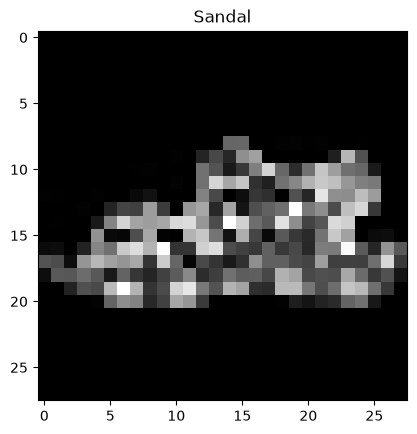

In [140]:
plt.imshow(test_samples[0].squeeze(), cmap='gray')
plt.title(class_names[test_labels[0]])

In [141]:
# Make predictions 
pred_probs = make_predictions(model=model_2,
                            data=test_samples)

# view the first two prediciton prob
pred_probs[:2]

tensor([[1.1646e-05, 3.2677e-07, 5.1909e-06, 9.4076e-06, 1.2371e-05, 9.9883e-01,
         1.4597e-05, 4.3395e-04, 2.0256e-04, 4.8187e-04],
        [2.8099e-03, 1.0243e-05, 1.5598e-01, 1.4502e-04, 7.9492e-02, 1.6520e-06,
         7.6153e-01, 1.1653e-07, 2.9297e-05, 4.7219e-07]])

In [142]:
# Convert predictions probs to labels 
pred_classes = pred_probs.argmax(dim=1)
pred_classes

tensor([5, 6, 6, 2, 3, 1, 2, 0, 6])

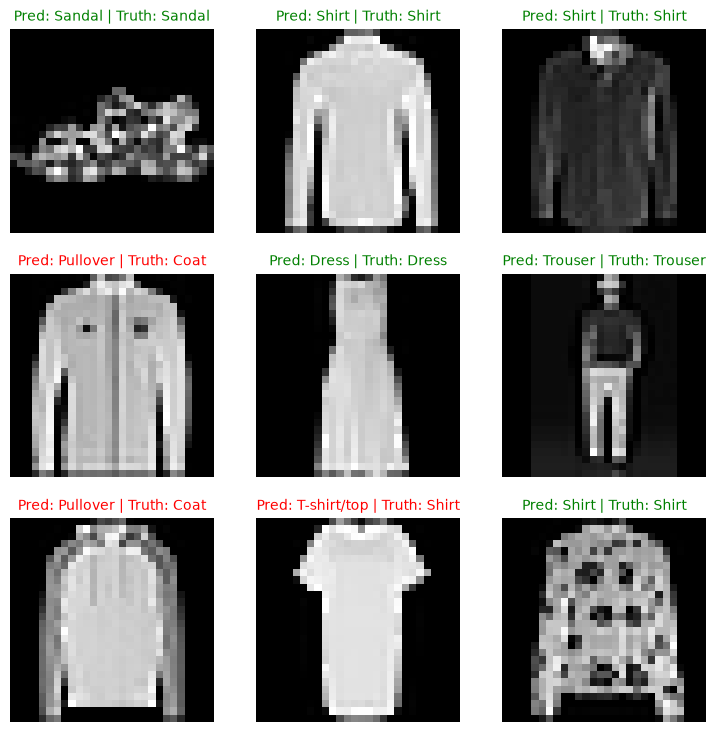

In [143]:
# Plot predictions
plt.figure(figsize=(9, 9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  # Create a subplot
  plt.subplot(nrows, ncols, i+1)

  # Plot the target image
  plt.imshow(sample.squeeze(), cmap="gray")

  # Find the prediction label (in text form, e.g. "Sandal")
  pred_label = class_names[pred_classes[i]]

  # Get the truth label (in text form, e.g. "T-shirt")
  truth_label = class_names[test_labels[i]] 

  # Create the title text of the plot
  title_text = f"Pred: {pred_label} | Truth: {truth_label}"
  
  # Check for equality and change title colour accordingly
  if pred_label == truth_label:
      plt.title(title_text, fontsize=10, c="g") # green text if correct
  else:
      plt.title(title_text, fontsize=10, c="r") # red text if wrong
  plt.axis(False);

## 10. Save and load best performing model 

In [147]:
from pathlib import Path 

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "03_pytorch_computer_vision_model_2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

In [148]:
MODEL_SAVE_PATH

WindowsPath('models/03_pytorch_computer_vision_model_2.pth')

In [150]:
torch.save(obj=model_2.state_dict(), f=MODEL_SAVE_PATH)

In [151]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 0.3550,  0.3632, -0.4597],
                        [ 0.3144,  0.2016, -0.1901],
                        [-0.3899,  0.2255,  0.1809]]],
              
              
                      [[[-0.5805,  0.3808,  0.0023],
                        [-0.1322,  0.6690,  0.1481],
                        [-0.1281,  0.2814,  0.1243]]],
              
              
                      [[[-0.5993,  0.0456,  0.2838],
                        [-1.0077, -0.8768,  0.0936],
                        [-0.9574, -0.7718, -0.1829]]],
              
              
                      [[[-0.4812, -1.3352, -0.4520],
                        [ 0.4817, -0.9107,  0.1865],
                        [ 0.3172, -0.0461,  0.4358]]],
              
              
                      [[[-0.0598,  0.4939, -0.2009],
                        [-0.2782,  0.3260, -0.3687],
                        [ 0.0755,  0.4521,  0.0133]]],
              
              
      

In [152]:
# Load the model and create a instance 
torch.manual_seed(42)

loaded_model_2 = FashionMNISTModelV2(input_shape=1,
                                    hidden_units=10,
                                    output_shape=len(class_names))

loaded_model_2.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

loaded_model_2.to(device)

FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [153]:
# Let's now evaluate the loaded model 
torch.manual_seed(42)

loaded_model_2_results = eval_model(model=loaded_model_2, 
            data_loader=test_dataloader,
            loss_fn=loss_fn, 
            accuracy_fn=accuracy_fn) 
loaded_model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.3020092844963074,
 'model_acc': 88.88777955271566}

In [154]:
model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.3020092844963074,
 'model_acc': 88.88777955271566}